# PHẦN 1: TẢI DỮ LIỆU VÀ KIỂM TRA CẤU TRÚC BAN ĐẦU

Cần có file `cardio_train.csv` nằm cùng thư mục với notebook này.
(Nếu chạy trên Google Colab: bấm biểu tượng thư mục bên trái, rồi upload file lên trước khi chạy.)

#### 1.1: Đọc dữ liệu

In [34]:
import pandas as pd
import matplotlib.pyplot as mpl

In [37]:
dataset_goc = pd.read_csv("cardio_train.csv", sep=";")

dataset_goc.columns = (dataset_goc.columns).str.lower()
dataset_goc.columns = (dataset_goc.columns).str.strip()

So_hang_ban_dau = dataset_goc.shape[0]
So_cot_ban_dau = dataset_goc.shape[1]
Bi_thieu_ban_dau = dataset_goc.isnull().sum().sum()

dataset_goc['age'] = dataset_goc['age'] / 365.25
dataset_goc['age'] = dataset_goc['age'].round(0)
dataset_goc['age'] = dataset_goc['age'].astype(int)

dataset_goc[["age"]].head()

,age
0,50
1,55
2,52
3,48
4,48


#### 1.2: Tổng quan dữ liệu

In [35]:
print("Kích thước:", dataset_goc.shape)
print("Các cột:")
print(dataset_goc.columns)

Kích thước: (70000, 13)
Các cột:
Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='object')


In [17]:
dataset_goc.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,50,2,168,62.0,110,80,1,1,0,0,1,0
1,1,55,1,156,85.0,140,90,3,1,0,0,1,1
2,2,52,1,165,64.0,130,70,3,1,0,0,0,1
3,3,48,2,169,82.0,150,100,1,1,0,0,1,1
4,4,48,1,156,56.0,100,60,1,1,0,0,0,0


In [18]:
dataset_goc.tail()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
69995,99993,53,2,168,76.0,120,80,1,1,1,0,1,0
69996,99995,62,1,158,126.0,140,90,2,2,0,0,1,1
69997,99996,52,2,183,105.0,180,90,3,1,0,1,0,1
69998,99998,61,1,163,72.0,135,80,1,2,0,0,0,1
69999,99999,56,1,170,72.0,120,80,2,1,0,0,1,0


In [36]:
dataset_goc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [20]:
dataset_goc.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,53.303157,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,6.760171,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,30.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,48.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,54.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,58.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,65.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


#### 1.3: Biểu đồ tròn cho các cột phân loại

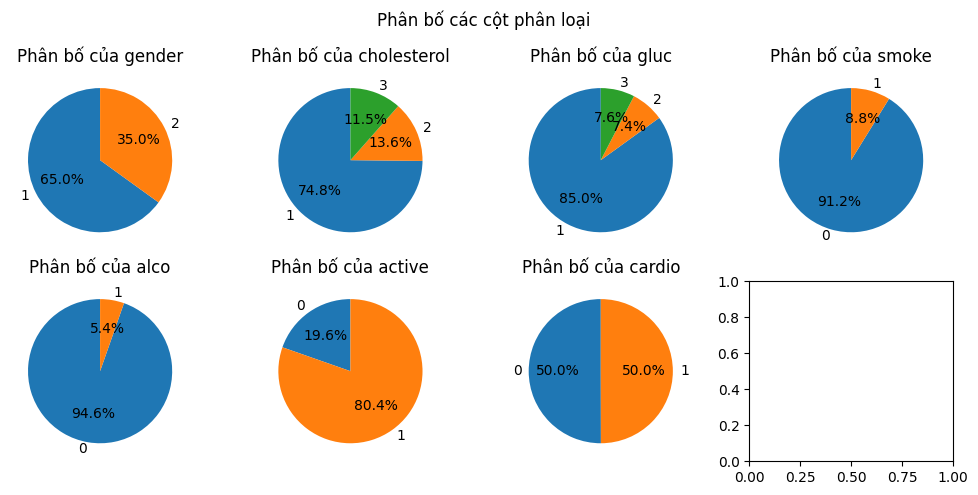

In [21]:
cot_phan_loai = ["gender", "cholesterol", "gluc", "smoke", "alco", "active", "cardio"]

fig, axes = mpl.subplots(2, 4, figsize=(10, 5))
axes = axes.flatten()

for i in range(0,7):
    cot = cot_phan_loai[i]
    dem = dataset_goc[cot].value_counts()
    dem = dem.sort_index()
    axes[i].pie(dem, labels=dem.index, autopct="%1.1f%%", startangle=90)
    axes[i].set_title("Phân bố của " + cot)

mpl.suptitle("Phân bố các cột phân loại")
mpl.tight_layout()
mpl.show()

#### 1.4: Biểu đồ tần suất của huyết áp (ap_hi và ap_lo)

Chia giá trị thành các khoảng rộng 10 (ví dụ 120 đến 130), chỉ vẽ các khoảng có từ 2000 bản ghi trở lên.

ap_hi 
- Nhỏ nhất: -150 
- Lớn nhất: 16020
ap_lo 
- Nhỏ nhất: -70 
- Lớn nhất: 11000


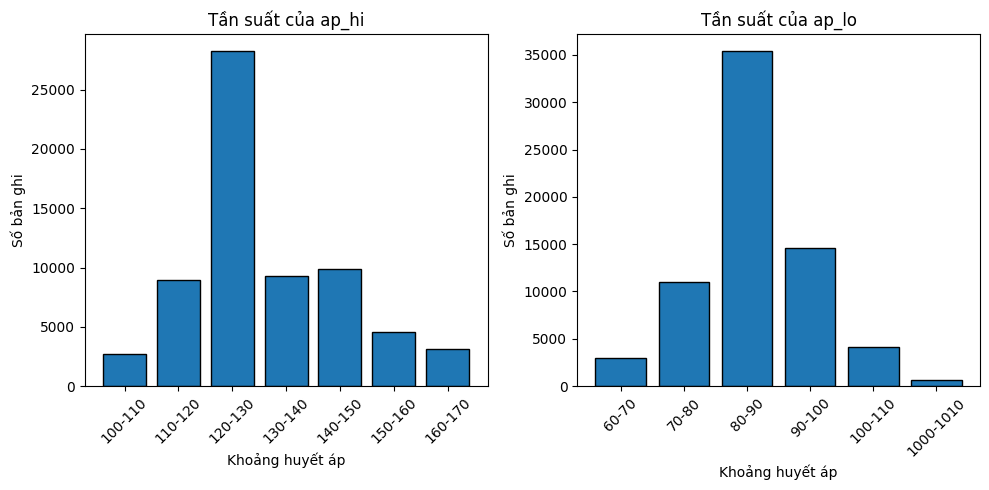

In [22]:
fig, axes = mpl.subplots(1, 2, figsize=(10, 5))

khoang_ap_hi = (dataset_goc["ap_hi"] // 10) * 10
khoang_ap_lo = (dataset_goc["ap_lo"] // 10) * 10

tan_suat_ap_hi = khoang_ap_hi.value_counts()
tan_suat_ap_hi = tan_suat_ap_hi.sort_index()

tan_suat_ap_lo = khoang_ap_lo.value_counts()
tan_suat_ap_lo = tan_suat_ap_lo.sort_index()

tan_suat_ap_hi = tan_suat_ap_hi[tan_suat_ap_hi >= 2000]
tan_suat_ap_lo = tan_suat_ap_lo[tan_suat_ap_lo >= 500]

nhan_ap_hi = []
for k in tan_suat_ap_hi.index:
    nhan_ap_hi.append(str(k) + "-" + str(k + 10))

nhan_ap_lo = []
for k in tan_suat_ap_lo.index:
    nhan_ap_lo.append(str(k) + "-" + str(k + 10))

axes[0].bar(nhan_ap_hi, tan_suat_ap_hi.values, edgecolor="black")
axes[0].set_title("Tần suất của ap_hi")
axes[0].set_xlabel("Khoảng huyết áp")
axes[0].set_ylabel("Số bản ghi")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(nhan_ap_lo, tan_suat_ap_lo.values, edgecolor="black")
axes[1].set_title("Tần suất của ap_lo")
axes[1].set_xlabel("Khoảng huyết áp")
axes[1].set_ylabel("Số bản ghi")
axes[1].tick_params(axis="x", rotation=45)

print("ap_hi \n- Nhỏ nhất:", dataset_goc["ap_hi"].min(), '\n' "- Lớn nhất:", dataset_goc["ap_hi"].max())
print("ap_lo \n- Nhỏ nhất:", dataset_goc["ap_lo"].min(), '\n' "- Lớn nhất:", dataset_goc["ap_lo"].max())

mpl.tight_layout()
mpl.show()

#### 1.5: Biểu đồ phân bố của các cột số còn lại

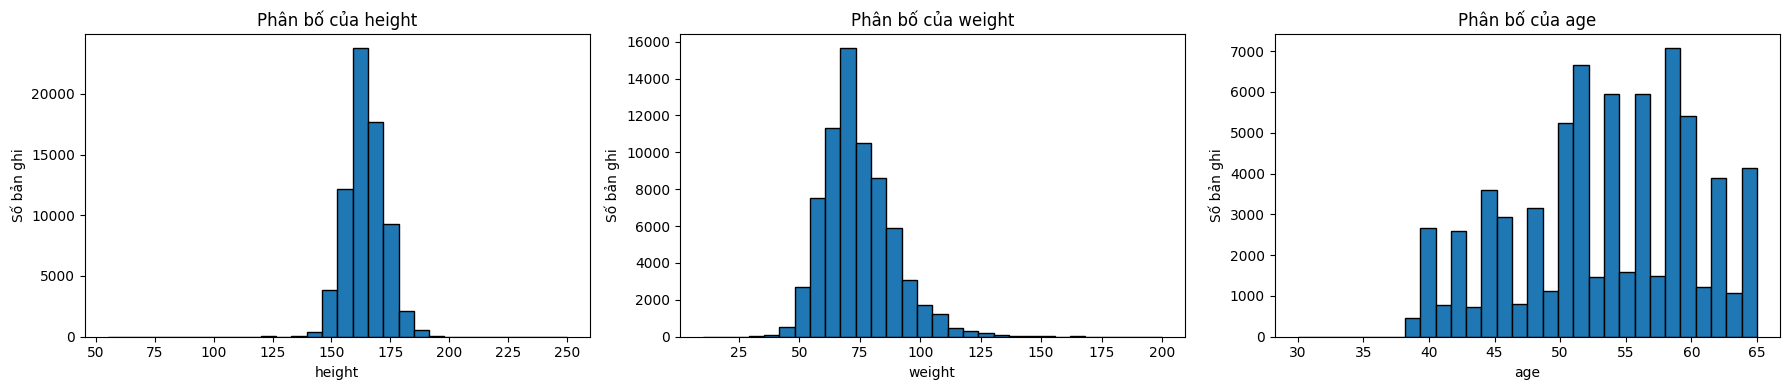

In [23]:
fig, axes = mpl.subplots(1, 3, figsize=(18, 4))

axes[0].hist(dataset_goc["height"], bins=30, edgecolor="black")
axes[0].set_title("Phân bố của height")
axes[0].set_xlabel("height")
axes[0].set_ylabel("Số bản ghi")

axes[1].hist(dataset_goc["weight"], bins=30, edgecolor="black")
axes[1].set_title("Phân bố của weight")
axes[1].set_xlabel("weight")
axes[1].set_ylabel("Số bản ghi")

axes[2].hist(dataset_goc["age"], bins=30, edgecolor="black")
axes[2].set_title("Phân bố của age")
axes[2].set_xlabel("age")
axes[2].set_ylabel("Số bản ghi")

mpl.tight_layout()
mpl.show()

# PHẦN 2: LÀM SẠCH VÀ TIỀN XỬ LÝ DỮ LIỆU

#### 2.1: Kiểm tra và xử lý bản ghi trùng lặp

In [24]:
Bi_trung_ca_id = dataset_goc.duplicated().sum()

cot_khong_id = list(dataset_goc.columns)
cot_khong_id.remove("id")
Bi_trung = dataset_goc.duplicated(subset=cot_khong_id).sum()

print("Số hàng trùng (tính cả id):", Bi_trung_ca_id)
print("Số hàng trùng (không tính id):", Bi_trung)

df_clean = dataset_goc.drop_duplicates(subset=cot_khong_id)

print("Số hàng trước:", len(dataset_goc))
print("Số hàng sau  :", len(df_clean))
print("Số hàng đã xóa:", len(dataset_goc) - len(df_clean))

Số hàng trùng (tính cả id): 0
Số hàng trùng (không tính id): 3821
Số hàng trước: 70000
Số hàng sau  : 66179
Số hàng đã xóa: 3821


#### 2.2: Kiểm tra và xử lý giá trị thiếu

Bỏ các cột rỗng hoàn toàn, sau đó bỏ các hàng có giá trị thiếu.

In [25]:
print("Số giá trị thiếu của từng cột:")
print(df_clean.isnull().sum())
print('\n')

so_cot_truoc = len(df_clean.columns)
df_clean = df_clean.dropna(axis=1, how="all")

print("Số cột đã xóa:", so_cot_truoc - len(df_clean.columns))
print("Số cột còn lại:", len(df_clean.columns))
print("Số giá trị thiếu còn lại:", df_clean.isnull().sum().sum())
print('\n')

so_hang_truoc = len(df_clean)
df_clean = df_clean.dropna(axis=0, how="any")

print("Số hàng đã xóa:", so_hang_truoc - len(df_clean))
print("Số hàng còn lại:", len(df_clean))
print("Số giá trị thiếu còn lại:", df_clean.isnull().sum().sum())

Số giá trị thiếu của từng cột:
id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64


Số cột đã xóa: 0
Số cột còn lại: 13
Số giá trị thiếu còn lại: 0


Số hàng đã xóa: 0
Số hàng còn lại: 66179
Số giá trị thiếu còn lại: 0


#### 2.3: Chuẩn hóa kiểu dữ liệu và định dạng

In [26]:
cot_so = ["id", "age", "gender", "height", "weight", "ap_hi", "ap_lo",
          "cholesterol", "gluc", "smoke", "alco", "active", "cardio"]

for i in cot_so:
    df_clean[i] = pd.to_numeric(df_clean[i], errors="coerce")

so_hang_truoc_khi_xoa = len(df_clean)
so_cot_truoc_khi_xoa = len(df_clean.columns)

df_clean = df_clean.dropna(axis=0, how="any")
df_clean = df_clean.dropna(axis=1, how="all")

print("Số hàng đã xóa:", so_hang_truoc_khi_xoa - len(df_clean))
print("Số cột đã xóa:", so_cot_truoc_khi_xoa - len(df_clean.columns))

Số hàng đã xóa: 0
Số cột đã xóa: 0


In [27]:
ma_hop_le = {
    "gender": [1, 2],
    "cholesterol": [1, 2, 3],
    "gluc": [1, 2, 3],
    "smoke": [0, 1],
    "alco": [0, 1],
    "active": [0, 1],
    "cardio": [0, 1],
}
for i in ma_hop_le:
    quan_sat = sorted(df_clean[i].unique().tolist())
    gia_tri_la = []
    for gia_tri in quan_sat:
        if gia_tri not in ma_hop_le[i]:
            gia_tri_la.append(gia_tri)
    print(i, "- giá trị quan sát:", quan_sat, "- giá trị lạ:", gia_tri_la)

gender - giá trị quan sát: [1, 2] - giá trị lạ: []
cholesterol - giá trị quan sát: [1, 2, 3] - giá trị lạ: []
gluc - giá trị quan sát: [1, 2, 3] - giá trị lạ: []
smoke - giá trị quan sát: [0, 1] - giá trị lạ: []
alco - giá trị quan sát: [0, 1] - giá trị lạ: []
active - giá trị quan sát: [0, 1] - giá trị lạ: []
cardio - giá trị quan sát: [0, 1] - giá trị lạ: []


In [28]:
df_clean.dtypes

,0
id,int64
age,int64
gender,int64
height,int64
weight,float64
ap_hi,int64
ap_lo,int64
cholesterol,int64
gluc,int64
smoke,int64


#### 2.4: Nhận diện và xử lý ngoại lệ ban đầu

Chỉ kiểm tra các cột đo liên tục (không kiểm tra các cột phân loại và cột 0/1).

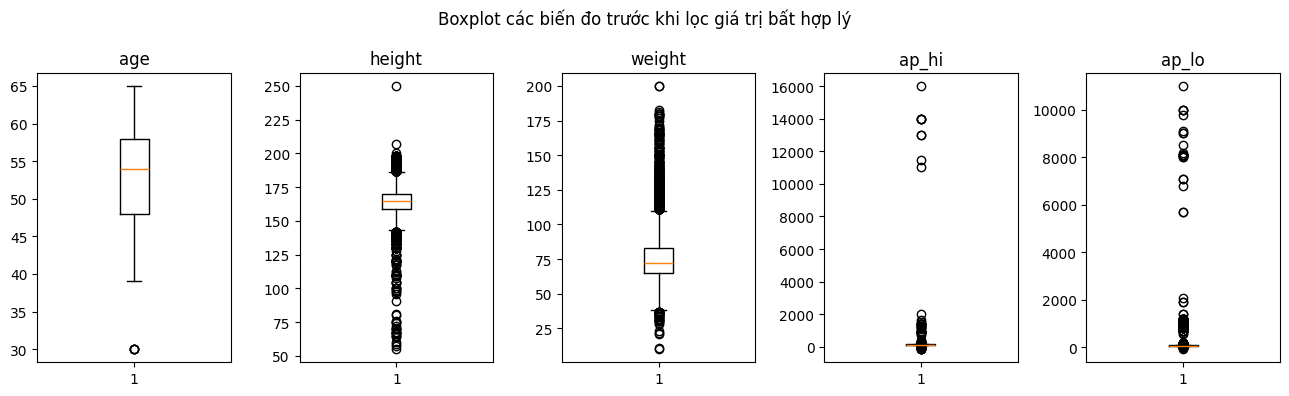

In [29]:
cot_lien_tuc = ["age", "height", "weight", "ap_hi", "ap_lo"]

fig, axes = mpl.subplots(1, 5, figsize=(13, 4))

for i in range(0,5):
    cot = cot_lien_tuc[i]
    axes[i].boxplot(df_clean[cot])
    axes[i].set_title(cot)

mpl.suptitle("Boxplot các biến đo trước khi lọc giá trị bất hợp lý")
mpl.tight_layout()
mpl.show()

In [30]:
ket_qua = []

for cot in cot_lien_tuc:
    q1 = df_clean[cot].quantile(0.25)
    q3 = df_clean[cot].quantile(0.75)
    iqr = q3 - q1
    can_duoi = q1 - 1.5 * iqr
    can_tren = q3 + 1.5 * iqr
    so_ngoai_le_can_duoi = (df_clean[cot] < can_duoi).sum()
    so_ngoai_le_can_tren = (df_clean[cot] > can_tren).sum()
    so_ngoai_le = so_ngoai_le_can_duoi + so_ngoai_le_can_tren

    ket_qua.append({
        "Cột": cot,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Cận dưới": can_duoi,
        "Cận trên": can_tren,
        "Số ngoại lệ IQR": so_ngoai_le,
    })

Bang_iqr = pd.DataFrame(ket_qua).set_index("Cột")
Bang_iqr.round(2)

,Q1,Q3,IQR,Cận dưới,Cận trên,Số ngoại lệ IQR
Cột,,,,,,
age,48.0,58.0,10.0,33.0,73.0,4
height,159.0,170.0,11.0,142.5,186.5,518
weight,65.0,83.0,18.0,38.0,110.0,1282
ap_hi,120.0,140.0,20.0,90.0,170.0,1434
ap_lo,80.0,90.0,10.0,65.0,105.0,4611


In [31]:
hop_le = (
    df_clean["age"].between(33, 73)
    & df_clean["height"].between(142, 186)
    & df_clean["weight"].between(38, 110)
    & df_clean["ap_hi"].between(90, 170)
    & df_clean["ap_lo"].between(65, 105)
    & (df_clean["ap_hi"] > df_clean["ap_lo"])
)

so_hang_bat_hop_ly = (~hop_le).sum()
df_clean = df_clean[hop_le]

print("Số hàng bất hợp lý đã xóa:", so_hang_bat_hop_ly)
print("Số hàng còn lại:", len(df_clean))

Số hàng bất hợp lý đã xóa: 6992
Số hàng còn lại: 59187


#### 2.5: Bảng so sánh trước và sau làm sạch

In [32]:
bang_so_sanh = pd.DataFrame({
    "Chỉ số": [
        "Tổng số hàng",
        "Tổng số cột",
        "Giá trị thiếu",
        "Hàng trùng (không tính id)",
        "Ngoại lệ / giá trị không hợp lý",
    ],
    "Trước làm sạch": [
        So_hang_ban_dau,
        So_cot_ban_dau,
        Bi_thieu_ban_dau,
        Bi_trung,
        Bang_iqr["Số ngoại lệ IQR"].sum(),
    ],
    "Sau làm sạch": [
        len(df_clean),
        df_clean.shape[1],
        df_clean.isnull().sum().sum(),
        df_clean.duplicated(subset=cot_khong_id).sum(),
        "Đã lọc miền bất hợp lý",
    ],
    "Phương pháp / Lý do": [
        "Bỏ " + str(Bi_trung) + " hàng trùng và " + str(so_hang_bat_hop_ly) + " hàng bất hợp lý",
        "Đổi cột age từ ngày sang năm",
        "Bỏ cột rỗng và hàng thiếu giá trị (nếu có)",
        "drop_duplicates(), giữ hàng đầu tiên",
        "IQR để nhận diện, chỉ xóa hàng ngoài miền hợp lý hoặc ap_hi <= ap_lo",
    ],
})

bang_so_sanh

,Chỉ số,Trước làm sạch,Sau làm sạch,Phương pháp / Lý do
0,Tổng số hàng,70000,59187,Bỏ 3821 hàng trùng và 6992 hàng bất hợp lý
1,Tổng số cột,13,13,Đổi cột age từ ngày sang năm
2,Giá trị thiếu,0,0,Bỏ cột rỗng và hàng thiếu giá trị (nếu có)
3,Hàng trùng (không tính id),3821,0,"drop_duplicates(), giữ hàng đầu tiên"
4,Ngoại lệ / giá trị không hợp lý,7849,Đã lọc miền bất hợp lý,"IQR để nhận diện, chỉ xóa hàng ngoài miền hợp ..."


#### 2.6: Xuất file dữ liệu đã làm sạch

File `cleaned_cardio.csv` sẽ được lưu cùng thư mục với notebook.

In [33]:
df_clean.to_csv("cleaned_cardio.csv", index=False)

print("Đã lưu file cleaned_cardio.csv")
print("Kích thước:", df_clean.shape[0], "hàng,", df_clean.shape[1], "cột")

Đã lưu file cleaned_cardio.csv
Kích thước: 59187 hàng, 13 cột
